# Taller T3 — Limpieza, escalado, encoding e indicadores de negocio

**Escenario ficticio:** *MercadoFlash* quiere analizar sus pedidos y, más adelante, construir modelos predictivos. El archivo de origen presenta inconsistencias típicas de sistemas reales.

### Entregable
Completa este notebook durante la clase. La evaluación se concentra en **decisiones justificadas y código reproducible**, no en “dejar el dataset perfecto”.

| Momento | Evidencia | Puntos |
|---|---|---:|
| 1 | Auditoría y diagnóstico | 15 |
| 2 | Sanitización y tipos | 20 |
| 3 | Nulos, duplicados y outliers | 20 |
| 4 | Indicadores de negocio | 20 |
| 5 | Encoding + escalado sin leakage | 20 |
| 6 | Conclusión ejecutiva | 5 |
| **Total** |  | **100** |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
RANDOM_STATE = 7

## Dataset del taller

Ejecuta la celda. **No modifiques la función generadora.** A partir de `df_raw` comienza tu trabajo.

In [2]:
# --- Carga del dataset del taller (funciona en Google Colab y en Jupyter local) ---
from pathlib import Path

RUTAS_POSIBLES = ["taller.csv", "data/taller.csv", "/content/taller.csv", "/content/data/taller.csv"]
ruta = next((p for p in RUTAS_POSIBLES if Path(p).exists()), None)

if ruta is None:
    try:
        from google.colab import files
        ruta = list(files.upload().keys())[0]
    except Exception:
        raise FileNotFoundError("Coloca 'taller.csv' junto al notebook (o en ./data/) y vuelve a ejecutar.")

df_raw = pd.read_csv(ruta)
print("Archivo cargado desde:", ruta, "| filas x columnas:", df_raw.shape)
df_raw.head()

Saving taller.csv to taller.csv
Archivo cargado desde: taller.csv | filas x columnas: (529, 12)


,orden,cliente,fecha,zona,canal_venta,familia,cantidad,precio,descuento,antiguedad_cliente_meses,rating,reclamo
0,MF-20388,CL-520,2026-08-06 00:00:00,Norte,Web,Deporte,1,130.0,0.18,1.0,3.8,No
1,MF-20496,CL-629,2026-04-16 00:00:00,CENTRO,app,Electrónica,3,159.0,0.04,9.0,4.9,0
2,MF-20138,CL-680,2026-03-28 00:00:00,CENTRO,APP,Ropa,4,$ 74,0.2,3.0,1.9,No
3,MF-20425,CL-521,s/f,Norte,WEB,Deporte,3,$ 126,0.13,28.0,NaN,No
4,MF-20065,CL-502,2026-01-07 00:00:00,SUR,LOCAL,Electrónica,2,73.0,0.18,20.0,4.1,No


## Momento 1 — Auditoría y diagnóstico (15 pts)

1. Reporta filas, columnas y tipos.
2. Construye una tabla con número y porcentaje de nulos por variable.
3. Identifica duplicados exactos y duplicados de `orden`.
4. Revisa las categorías de `zona`, `canal_venta` y `reclamo`.
5. Escribe **tres problemas** que deban corregirse antes de un análisis.

In [3]:
# TODO 1.1 — dimensiones, tipos y duplicados
print("Filas:", df_raw.shape[0], "| Columnas:", df_raw.shape[1])
print("\nVariables:", list(df_raw.columns))

print("\n--- Tipos detectados por pandas ---")
df_raw.info()

print("\n--- Duplicados ---")
print("Duplicados exactos (fila completa):", df_raw.duplicated().sum())
print("Duplicados de la clave de negocio 'orden':", df_raw["orden"].duplicated().sum())
print("¿'orden' es único?:", df_raw["orden"].is_unique)

display(df_raw.head())

Filas: 529 | Columnas: 12

Variables: ['orden', 'cliente', 'fecha', 'zona', 'canal_venta', 'familia', 'cantidad', 'precio', 'descuento', 'antiguedad_cliente_meses', 'rating', 'reclamo']

--- Tipos detectados por pandas ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   orden                     529 non-null    object 
 1   cliente                   529 non-null    object 
 2   fecha                     529 non-null    object 
 3   zona                      508 non-null    object 
 4   canal_venta               529 non-null    object 
 5   familia                   529 non-null    object 
 6   cantidad                  529 non-null    int64  
 7   precio                    497 non-null    object 
 8   descuento                 488 non-null    object 
 9   antiguedad_cliente_meses  492 non-null    float64
 10  rating 

,orden,cliente,fecha,zona,canal_venta,familia,cantidad,precio,descuento,antiguedad_cliente_meses,rating,reclamo
0,MF-20388,CL-520,2026-08-06 00:00:00,Norte,Web,Deporte,1,130.0,0.18,1.0,3.8,No
1,MF-20496,CL-629,2026-04-16 00:00:00,CENTRO,app,Electrónica,3,159.0,0.04,9.0,4.9,0
2,MF-20138,CL-680,2026-03-28 00:00:00,CENTRO,APP,Ropa,4,$ 74,0.2,3.0,1.9,No
3,MF-20425,CL-521,s/f,Norte,WEB,Deporte,3,$ 126,0.13,28.0,NaN,No
4,MF-20065,CL-502,2026-01-07 00:00:00,SUR,LOCAL,Electrónica,2,73.0,0.18,20.0,4.1,No


¿Qué variables presentan un tipo de dato que no parece corresponder con la información que almacenan?


*   R: Son las variables de Precio y Descuento que deberian tener valores numericos unicamente pero poseen variables tipo object

,dtype,n_nulos,%_nulos,n_unicos
descuento,object,41,7.75,50
antiguedad_cliente_meses,float64,37,6.99,61
precio,object,32,6.05,212
rating,float64,26,4.91,32
zona,object,21,3.97,9
fecha,object,0,0.00,164
orden,object,0,0.00,520
cliente,object,0,0.00,180
cantidad,int64,0,0.00,10
familia,object,0,0.00,4


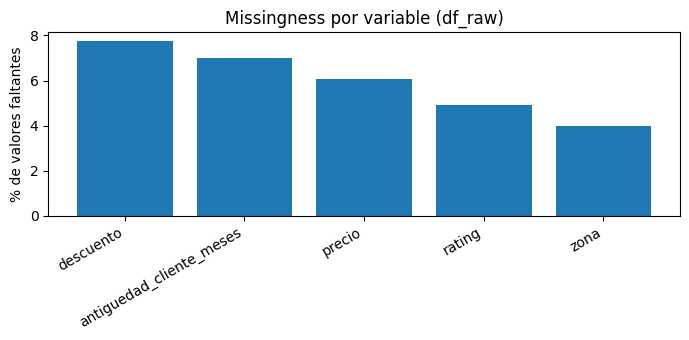

In [4]:
# TODO 1.2 — tabla de nulos (todavía NO se imputa nada)
perfil = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_nulos": df_raw.isna().sum(),
    "%_nulos": (df_raw.isna().mean() * 100).round(2),
    "n_unicos": df_raw.nunique(dropna=True),
}).sort_values("%_nulos", ascending=False)

display(perfil)

faltantes = (df_raw.isna().mean() * 100)
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 3.5))
plt.bar(faltantes.index, faltantes.values)
plt.ylabel("% de valores faltantes")
plt.title("Missingness por variable (df_raw)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

¿Todas las variables con valores faltantes deberían tratarse de la misma manera?


No, no todas las variables deben tratarse igual. La estrategia de tratamiento de nulos depende de la naturaleza de la variable y del impacto de la información faltante

*   Variables Categóricas (como zona): Si no hay forma de deducir el dato, es mejor crear una categoría nueva (ej. 'desconocida') para no inventar información geográfica que sesgue el análisis.
*   Variables con Dependencia Lógica (como precio): Es más preciso imputar basándose en otras variables. Por ejemplo, el precio de un artículo de 'Electrónica' será más cercano a la mediana de su propia familia que a la mediana global del dataset
*   Variables de Comportamiento (como descuento): A veces el nulo es informativo. Podría significar que no hubo descuento o que hubo un error en el registro. Imputar con la mediana por canal de venta ayuda a mantener la coherencia con la política comercial.
*   Variables Críticas (como fecha): En este caso, si la fecha es inválida (NaT), a menudo es mejor no imputarla para no inventar estacionalidad, sino marcarla con un indicador (como fecha_valida = 0) para excluirla solo de análisis temporales.



In [5]:
# TODO 1.3 — inspección de categorías y de tipos sospechosos
for col in ["zona", "canal_venta", "familia", "reclamo"]:
    print(f"\n--- {col} ---")
    print(df_raw[col].value_counts(dropna=False))

print("\n¿Cuántas categorías REALES hay detrás del ruido de texto?")
for col in ["zona", "canal_venta"]:
    limpio = df_raw[col].astype("string").str.strip().str.lower()
    print(f"  {col}: {df_raw[col].nunique()} categorías crudas -> {limpio.nunique()} tras strip() + lower()")

# Variables numéricas guardadas como texto
mask_precio_txt = df_raw["precio"].astype("string").str.contains(r"[^0-9\.]", na=False)
mask_desc_txt = df_raw["descuento"].astype("string").str.contains(r"[^0-9\.]", na=False)
print("\nValores no numéricos en 'precio':", df_raw.loc[mask_precio_txt, "precio"].unique()[:6],
      "->", int(mask_precio_txt.sum()), "registros")
print("Valores no numéricos en 'descuento':", df_raw.loc[mask_desc_txt, "descuento"].unique()[:6],
      "->", int(mask_desc_txt.sum()), "registros")

# Fechas que ningún formato puede interpretar
fechas_prueba = pd.to_datetime(df_raw["fecha"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
print("\nFechas fuera del formato principal:", df_raw.loc[fechas_prueba.isna(), "fecha"].unique())

# Valores imposibles
antig = pd.to_numeric(df_raw["antiguedad_cliente_meses"], errors="coerce")
print("antiguedad_cliente_meses -> min:", antig.min(), "| max:", antig.max())
print("cantidad -> valores observados:", sorted(df_raw["cantidad"].unique()))


--- zona ---
zona
CENTRO     105
Centro      89
 centro     87
SUR         42
Norte       38
sur         38
 norte      38
Sur         37
NORTE       34
NaN         21
Name: count, dtype: int64

--- canal_venta ---
canal_venta
WEB       88
App       79
 web      78
Web       72
APP       66
app       52
 local    38
LOCAL     33
Local     23
Name: count, dtype: int64

--- familia ---
familia
Hogar          149
Electrónica    131
Ropa           125
Deporte        124
Name: count, dtype: int64

--- reclamo ---
reclamo
No    421
Sí     57
0      45
1       6
Name: count, dtype: int64

¿Cuántas categorías REALES hay detrás del ruido de texto?
  zona: 9 categorías crudas -> 3 tras strip() + lower()
  canal_venta: 9 categorías crudas -> 3 tras strip() + lower()

Valores no numéricos en 'precio': ['$ 74' '$ 126' '$ 78' '$ 219' '$ 79' '$ 85'] -> 56 registros
Valores no numéricos en 'descuento': ['1%' '2%' '8%' '4%' '19%' '5%'] -> 50 registros

Fechas fuera del formato principal: ['s/f' '32-05

**Diagnóstico (3 problemas):**

1. **Variables monetarias almacenadas como texto.** `precio` trae 56 registros escritos como `"$ 74"` y `descuento` trae 50 escritos como `"12%"`, por lo que pandas lee ambas columnas como `object`. Hoy no se puede calcular ninguna venta: `cantidad * precio` falla o se calcula solo sobre parte de los datos, y `descuento` mezcla dos escalas distintas (0.12 y 12).
2. **Categorías duplicadas por formato de texto.** `zona` presenta 9 valores distintos (`"Norte"`, `" norte "`, `"NORTE"`, …) que en realidad son **3** zonas, y `canal_venta` presenta 9 que en realidad son **3** canales. Un `groupby("canal_venta")` reportaría hoy 9 canales inexistentes y repartiría las ventas de "web" en tres grupos.
3. **Duplicados de la clave de negocio.** Hay 9 filas exactamente repetidas que generan 9 valores duplicados de `orden` (1,7% del archivo). Al no ser `orden` único, las ventas totales, el número de pedidos y la tasa de reclamos quedan inflados.

*Otros hallazgos que también se corrigen más abajo:* `reclamo` mezcla cuatro representaciones (`No`, `Sí`, `0`, `1`); `fecha` incluye valores no interpretables (`s/f`, `32-05-2026`); `antiguedad_cliente_meses` contiene valores imposibles (`-12`, `300`, `500` meses).

## Momento 2 — Sanitización y tipos (20 pts)

Trabaja sobre `df = df_raw.copy()`.

- estandariza `zona` y `canal_venta`;
- convierte `precio` a numérico;
- convierte `descuento` a proporción numérica entre 0 y 1;
- convierte `fecha` a `datetime`;
- convierte `reclamo` a 0/1;
- justifica brevemente qué haces con fechas inválidas.

In [6]:
# TODO 2 — sanitización
# Orden: texto -> numéricos -> fechas -> variable objetivo -> validación
# Solo transformaciones DETERMINISTAS (no dependen de estadísticos del dataset),
# por eso pueden aplicarse antes del split sin riesgo de data leakage.

df = df_raw.copy()

# --- 2.1 Estandarización de categorías (espacios + mayúsculas) ---
for col in ["zona", "canal_venta", "familia"]:
    df[col] = (df[col].astype("string")
                      .str.strip()
                      .str.lower()
                      .replace({"": pd.NA, "nan": pd.NA, "none": pd.NA}))

# Reglas explícitas de negocio por si aparecen abreviaturas
df["zona"] = df["zona"].replace({"nte": "norte", "ctro": "centro"})

# --- 2.2 precio -> numérico (quita "$", espacios y cualquier símbolo) ---
df["precio"] = pd.to_numeric(
    df["precio"].astype("string").str.replace(r"[^0-9\.\-]", "", regex=True).replace("", pd.NA),
    errors="coerce"
).astype("float64")

# --- 2.2b descuento -> proporción en [0, 1] (admite 0.15 y "15%") ---
desc = df["descuento"].astype("string").str.strip().str.replace(",", ".", regex=False)
es_pct = desc.str.endswith("%", na=False)
desc_num = pd.to_numeric(desc.str.replace("%", "", regex=False), errors="coerce")
df["descuento"] = pd.to_numeric(np.where(es_pct, desc_num / 100, desc_num), errors="coerce")
df.loc[df["descuento"] > 1, "descuento"] = df.loc[df["descuento"] > 1, "descuento"] / 100   # "20" sin símbolo
df.loc[(df["descuento"] < 0) | (df["descuento"] > 1), "descuento"] = np.nan                 # resto = no interpretable

# --- 2.3 fecha -> datetime probando formatos explícitos, del más frecuente al más raro ---
# Se evita dayfirst=True sobre todo el archivo: convertiría "2026-08-06" (ISO) en 6 de agosto -> 8 de junio.
fecha_txt = df["fecha"].astype("string").str.strip()
fecha_dt = None
for fmt in ["%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%d-%m-%Y", "%d/%m/%Y"]:
    parsed = pd.to_datetime(fecha_txt, format=fmt, errors="coerce")
    fecha_dt = parsed if fecha_dt is None else fecha_dt.fillna(parsed)
df["fecha"] = fecha_dt
n_nat = int(df["fecha"].isna().sum())

# --- 2.4 reclamo -> binaria 0/1 ---
df["reclamo"] = (df["reclamo"].astype("string").str.strip().str.lower()
                 .map({"sí": 1, "si": 1, "s": 1, "1": 1, "true": 1,
                       "no": 0, "n": 0, "0": 0, "false": 0}))
df["reclamo"] = pd.to_numeric(df["reclamo"], errors="coerce").astype("Int64")

# --- 2.5 resto de numéricas ---
for col in ["cantidad", "antiguedad_cliente_meses", "rating"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# --- Validación del Momento 2 ---
print("--- Tipos después de sanitizar ---")
print(df[["precio", "descuento", "fecha", "reclamo", "cantidad"]].dtypes)
print("\nzona:", sorted(df["zona"].dropna().unique().tolist()))
print("canal_venta:", sorted(df["canal_venta"].dropna().unique().tolist()))
print("familia:", sorted(df["familia"].dropna().unique().tolist()))
print(f"\ndescuento -> min = {df['descuento'].min():.2f} | max = {df['descuento'].max():.2f}  (debe estar en [0, 1])")
print("reclamo -> valores:", sorted(df["reclamo"].dropna().unique().tolist()),
      f"| tasa de reclamo = {df['reclamo'].mean():.1%}")
print(f"fecha -> {n_nat} valores inválidos (NaT) = {n_nat/len(df):.1%} de las filas:",
      df_raw.loc[df["fecha"].isna(), "fecha"].unique())

--- Tipos después de sanitizar ---
precio              float64
descuento           float64
fecha        datetime64[ns]
reclamo               Int64
cantidad              int64
dtype: object

zona: ['centro', 'norte', 'sur']
canal_venta: ['app', 'local', 'web']
familia: ['deporte', 'electrónica', 'hogar', 'ropa']

descuento -> min = 0.00 | max = 0.29  (debe estar en [0, 1])
reclamo -> valores: [0, 1] | tasa de reclamo = 11.9%
fecha -> 4 valores inválidos (NaT) = 0.8% de las filas: ['s/f' '32-05-2026']


**Decisión sobre fechas inválidas:** son 4 registros (`s/f` y `32-05-2026`), es decir **0,8 %** de las filas. **No se eliminan y no se imputan.** Eliminarlas borraría ventas reales y válidas (cantidad, precio y reclamo sí están registrados), e imputarlas —con la moda o con la fecha mediana— inventaría un período de compra y distorsionaría cualquier análisis de estacionalidad. La decisión es **conservar la fila, dejar `fecha = NaT` y marcarla con `fecha_valida = 0`**, de modo que los indicadores temporales (`mes`, `fin_de_semana`) queden nulos solo en esos casos y puedan excluirse explícitamente de los análisis por fecha, mientras las ventas siguen sumando en los totales.

## Momento 3 — Nulos, duplicados y outliers (20 pts)

Diseña una estrategia razonable para:

- `zona`;
- `precio`;
- `descuento`;
- `antiguedad_cliente_meses`;
- `rating`.

Además:
- elimina pedidos duplicados usando la clave adecuada;
- detecta outliers en `cantidad` con IQR **sin eliminarlos automáticamente**;
- corrige valores imposibles en `antiguedad_cliente_meses`.

> Incluye al menos **dos indicadores de missingness** (`*_faltaba`).

Filas antes: 529 | duplicados exactos: 9 | duplicados de 'orden': 9
Filas después: 520 | ¿'orden' es único?: True

Indicadores creados: ['zona_faltaba', 'precio_faltaba', 'descuento_faltaba', 'antiguedad_faltaba', 'rating_faltaba', 'fecha_valida']

Valores imposibles en antiguedad: 3 -> [-12.0, 300.0, 500.0]

IQR cantidad -> Q1=2.0  Q3=4.0  IQR=2.0  límites = [-1.0, 7.0]
Outliers detectados (marcados, NO eliminados): 6


,orden,cliente,canal_venta,familia,cantidad,precio
15,MF-20145,CL-666,app,ropa,90,141.0
112,MF-20228,CL-558,web,hogar,60,51.0
116,MF-20261,CL-680,app,electrónica,60,73.0
136,MF-20026,CL-688,app,ropa,60,96.0
360,MF-20504,CL-556,web,deporte,8,90.0
394,MF-20320,CL-589,web,deporte,90,78.0


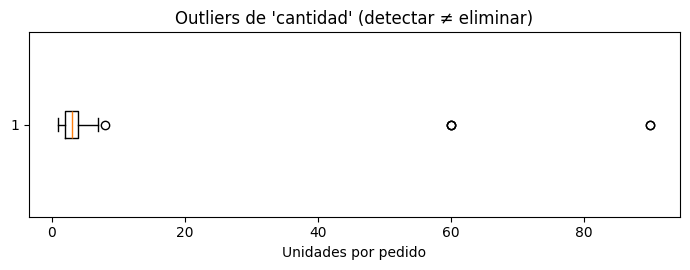


Nulos restantes en las variables tratadas:
zona                        0
precio                      0
descuento                   0
antiguedad_cliente_meses    0
rating                      0
dtype: int64


In [7]:
# TODO 3 — imputación, duplicados y outliers
# ORDEN DEL PIPELINE (importante): primero se quita lo que distorsiona los estadísticos,
# después se calculan los estadísticos de imputación.
#   3.1 duplicados        -> las filas repetidas sesgan medianas y conteos
#   3.2 marcas de faltante -> deben registrarse ANTES de rellenar
#   3.3 valores imposibles -> se convierten en NaN ANTES de imputar (si no, contaminan la mediana)
#   3.4 imputación
#   3.5 outliers          -> se detectan, NO se eliminan

# --- 3.1 Duplicados: la clave conceptual de un pedido es 'orden' ---
print("Filas antes:", len(df),
      "| duplicados exactos:", df.duplicated().sum(),
      "| duplicados de 'orden':", df["orden"].duplicated().sum())
df = df.drop_duplicates(subset="orden", keep="first").copy()
print("Filas después:", len(df), "| ¿'orden' es único?:", df["orden"].is_unique)

# --- 3.2 Indicadores de missingness (se conserva la información de la ausencia) ---
cols_con_nulos = ["zona", "precio", "descuento", "antiguedad_cliente_meses", "rating"]
for col in cols_con_nulos:
    df[f"{col}_faltaba"] = df[col].isna().astype(int)
df = df.rename(columns={"antiguedad_cliente_meses_faltaba": "antiguedad_faltaba"})
df["fecha_valida"] = df["fecha"].notna().astype(int)
print("\nIndicadores creados:", [c for c in df.columns if c.endswith("_faltaba")] + ["fecha_valida"])

# --- 3.3 Valores imposibles en antiguedad_cliente_meses ---
# Regla de negocio: la antigüedad no puede ser negativa ni superar 120 meses (10 años de operación).
ANTIG_MIN, ANTIG_MAX = 0, 120
mask_imposible = (df["antiguedad_cliente_meses"].notna()
                  & ~df["antiguedad_cliente_meses"].between(ANTIG_MIN, ANTIG_MAX))
print("\nValores imposibles en antiguedad:", int(mask_imposible.sum()), "->",
      sorted(df.loc[mask_imposible, "antiguedad_cliente_meses"].unique().tolist()))
df["antiguedad_invalida"] = mask_imposible.astype(int)          # se deja huella del error
df.loc[mask_imposible, "antiguedad_cliente_meses"] = np.nan     # pasan a ser "faltantes" y se imputan

# --- 3.4 Imputación (una estrategia por variable, según lo que representa) ---
df["zona"] = df["zona"].astype("string").fillna("desconocida")                       # categórica: no se inventa zona

df["precio"] = df["precio"].fillna(df.groupby("familia")["precio"].transform("median"))   # el precio depende del producto
df["precio"] = df["precio"].fillna(df["precio"].median())                                 # respaldo global

df["descuento"] = df["descuento"].fillna(df.groupby("canal_venta")["descuento"].transform("median"))  # política por canal
df["descuento"] = df["descuento"].fillna(df["descuento"].median())

df["antiguedad_cliente_meses"] = df["antiguedad_cliente_meses"].fillna(df["antiguedad_cliente_meses"].median())
df["rating"] = df["rating"].fillna(df["rating"].median())       # mediana: distribución asimétrica y acotada 1-5

# --- 3.5 Outliers de 'cantidad' por IQR: SE MARCAN, NO SE ELIMINAN ---
q1, q3 = df["cantidad"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df["cantidad_outlier"] = (~df["cantidad"].between(lim_inf, lim_sup)).astype(int)

print(f"\nIQR cantidad -> Q1={q1:.1f}  Q3={q3:.1f}  IQR={iqr:.1f}  límites = [{lim_inf:.1f}, {lim_sup:.1f}]")
print("Outliers detectados (marcados, NO eliminados):", int(df["cantidad_outlier"].sum()))
display(df.loc[df["cantidad_outlier"] == 1, ["orden", "cliente", "canal_venta", "familia", "cantidad", "precio"]])

# Decisión sobre los outliers: los pedidos de 60 y 90 unidades son compatibles con una compra
# mayorista o corporativa (precio unitario normal, clientes distintos), no con un error de tipeo.
# En un proyecto real se validarían contra el sistema de facturación antes de tocarlos; aquí se
# conservan y se marcan, para poder repetir cualquier análisis con y sin ellos.

plt.figure(figsize=(7, 2.8))
plt.boxplot(df["cantidad"], vert=False)
plt.xlabel("Unidades por pedido")
plt.title("Outliers de 'cantidad' (detectar ≠ eliminar)")
plt.tight_layout()
plt.show()

print("\nNulos restantes en las variables tratadas:")
print(df[cols_con_nulos].isna().sum())


¿Por qué el hecho de que una variable estuviera ausente podría contener información útil?



 En ciencia de datos, esto se conoce como información oculta o missingness no aleatoria, y es útil por varias razones:

*    Segmentación de comportamiento: Un cliente que no deja un rating puede ser sistemáticamente distinto a uno que sí lo hace (por ejemplo, los clientes muy insatisfechos o muy satisfechos tienden a calificar más, mientras que los neutrales no). Si solo analizamos los observados, sesgamos el promedio.
*    Fallas en procesos de negocio: Si notamos que los nulos en precio se concentran en el canal_venta 'app', esto podría indicar un bug técnico en la aplicación que no está capturando el dato, lo cual es un hallazgo crítico para el equipo de IT.
*    Señal predictiva para ML: Para un modelo, el hecho de que descuento falte podría ser un predictor más fuerte de un reclamo que el valor del descuento en sí mismo. Quizás los pedidos sin descuento registrado son órdenes manuales más propensas a error.
*    Transparencia en la imputación: Al crear la variable *_faltaba, permitimos que el modelo diferencie entre un 7% de descuento 'real' y un 7% que nosotros inventamos (imputamos) para que el código no fallara.



¿Cuál es la diferencia entre un valor faltante y un valor numérico que es imposible desde el punto de vista del negocio?




*   Valor Faltante (Missing Value): Es una ausencia de información. Simplemente no sabemos qué ocurrió (por ejemplo, el cliente no calificó el producto en rating). No hay datos para procesar, por lo que debemos decidir si imputar o descartar basándonos en la probabilidad de que esa ausencia sea aleatoria o no.

*   Valor Numérico Imposible: Es una falla en la calidad o lógica del dato. El dato existe, pero contradice la realidad del negocio (por ejemplo, una antiguedad_cliente_meses de -12 o 500 años). Esto suele ser error de captura, bug de sistema o ruido en la integración

### Justificación de imputación

**Orden aplicado:** duplicados → marcas de faltante → valores imposibles → imputación → outliers. Deduplicar primero evita que 9 filas repetidas sesguen las medianas, y convertir los valores imposibles (`-12`, `300`, `500` meses) en `NaN` antes de imputar impide que esos errores contaminen el estadístico con el que se rellena.

**Estrategias:** `zona` se imputa con la categoría explícita **"desconocida"** (4 % de nulos): no hay forma de deducir la zona y forzar la moda inventaría concentración geográfica. `precio` se imputa con la **mediana por `familia`**, porque el precio depende del tipo de producto y una mediana global mezclaría electrónica con ropa; `descuento` con la **mediana por `canal_venta`**, ya que la política comercial cambia entre app, web y local —imputar 0 habría sido peor, porque asume que no hubo descuento cuando en realidad no se registró—. `antiguedad_cliente_meses` y `rating` usan la **mediana global**, más robusta que la media ante distribuciones asimétricas y ante los valores extremos ya detectados.

**Qué se altera:** toda imputación reduce artificialmente la varianza y refuerza el centro de la distribución (el 6-8 % de `precio`, `descuento` y `antigüedad` pasa a valer exactamente la mediana), lo que subestima la incertidumbre y debilita correlaciones reales. Por eso se conservan los indicadores `*_faltaba`: permiten separar "valor observado" de "valor imputado", detectar si la ausencia era informativa (por ejemplo, pedidos sin precio registrado concentrados en un canal) y repetir cualquier conclusión solo con los datos observados.

## Momento 4 — Indicadores de negocio (20 pts)

Crea como mínimo las siguientes variables:

- `venta_bruta = cantidad * precio`;
- `monto_descuento`;
- `venta_neta`;
- `descuento_alto` (define y documenta tu umbral);
- una variable temporal derivada de `fecha`;
- **un indicador adicional diseñado por el equipo**.

Luego construye una tabla resumen por `canal_venta` con:
- número de pedidos;
- ventas netas;
- ticket promedio;
- tasa de reclamos.

In [8]:
# TODO 4.1 — crear indicadores
# --- 4.1 Variables monetarias ---
df["venta_bruta"] = df["cantidad"] * df["precio"]
df["monto_descuento"] = df["venta_bruta"] * df["descuento"]
df["venta_neta"] = df["venta_bruta"] - df["monto_descuento"]      # venta_neta = bruta - descuento

# --- 4.2 Indicador de descuento alto ---
# Umbral = 0.20 (20 %). Criterio: es el punto donde el descuento deja de ser promocional habitual
# (la mediana es ~7 % y el p90 ~17 %), por lo que marca pedidos excepcionales que conviene auditar.
UMBRAL_DESC_ALTO = 0.20
df["descuento_alto"] = (df["descuento"] >= UMBRAL_DESC_ALTO).astype(int)
print(f"Umbral descuento_alto = {UMBRAL_DESC_ALTO:.0%}  (mediana = {df['descuento'].median():.2f}, "
      f"p90 = {df['descuento'].quantile(0.90):.2f}) -> {df['descuento_alto'].mean():.1%} de los pedidos")

# --- 4.3 Variables temporales (quedan nulas donde la fecha era inválida) ---
df["mes"] = df["fecha"].dt.month.astype("Int64")
df["dia_semana"] = df["fecha"].dt.dayofweek.astype("Int64")
df["fin_de_semana"] = (df["fecha"].dt.dayofweek >= 5).astype("Int64").where(df["fecha"].notna())

# --- 4.4 Indicador diseñado por el equipo ---
# pedidos_cliente: frecuencia de compra del cliente en el período (recurrencia).
# cliente_nuevo: pedido realizado por un cliente con 3 meses o menos de antigüedad.
df["pedidos_cliente"] = df.groupby("cliente")["orden"].transform("nunique")
df["cliente_nuevo"] = (df["antiguedad_cliente_meses"] <= 3).astype(int)

print(f"\npedidos_cliente -> min={df['pedidos_cliente'].min()}, mediana={df['pedidos_cliente'].median():.0f}, "
      f"max={df['pedidos_cliente'].max()} | clientes nuevos: {df['cliente_nuevo'].mean():.1%} de los pedidos")

display(df[["orden", "cantidad", "precio", "descuento", "venta_bruta", "monto_descuento", "venta_neta",
            "descuento_alto", "mes", "fin_de_semana", "pedidos_cliente", "cliente_nuevo"]].head())

Umbral descuento_alto = 20%  (mediana = 0.07, p90 = 0.17) -> 6.2% de los pedidos

pedidos_cliente -> min=1, mediana=4, max=9 | clientes nuevos: 10.4% de los pedidos


,orden,cantidad,precio,descuento,venta_bruta,monto_descuento,venta_neta,descuento_alto,mes,fin_de_semana,pedidos_cliente,cliente_nuevo
0,MF-20388,1,130.0,0.18,130.0,23.40,106.60,0,8,0,4,1
1,MF-20496,3,159.0,0.04,477.0,19.08,457.92,0,4,0,5,0
2,MF-20138,4,74.0,0.20,296.0,59.20,236.80,1,3,1,7,1
3,MF-20425,3,126.0,0.13,378.0,49.14,328.86,0,<NA>,<NA>,5,0
4,MF-20065,2,73.0,0.18,146.0,26.28,119.72,0,1,0,3,0


,canal_venta,pedidos,ventas_netas,ticket_promedio,unidades,tasa_reclamos_%,descuento_medio_%
0,app,193,77736.0,402.8,801,14.0,8.2
2,web,235,77188.0,328.5,873,11.1,8.5
1,local,92,22212.0,241.4,284,9.8,7.8


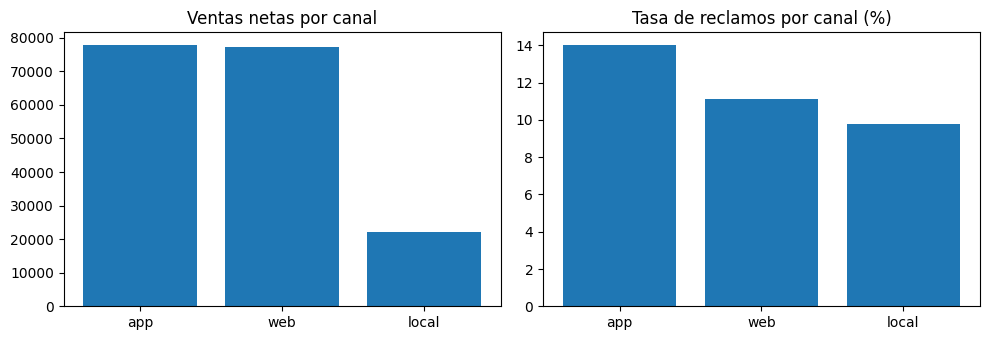

In [9]:
# TODO 4.2 — tabla resumen por canal
resumen_canal = (
    df.groupby("canal_venta", as_index=False)
      .agg(pedidos=("orden", "nunique"),
           ventas_netas=("venta_neta", "sum"),
           ticket_promedio=("venta_neta", "mean"),
           tasa_reclamos=("reclamo", "mean"),
           descuento_medio=("descuento", "mean"),
           unidades=("cantidad", "sum"))
      .sort_values("ventas_netas", ascending=False)
)
resumen_canal["ventas_netas"] = resumen_canal["ventas_netas"].round(0)
resumen_canal["ticket_promedio"] = resumen_canal["ticket_promedio"].round(1)
resumen_canal["tasa_reclamos_%"] = (100 * resumen_canal["tasa_reclamos"].astype(float)).round(1)
resumen_canal["descuento_medio_%"] = (100 * resumen_canal["descuento_medio"]).round(1)
resumen_canal = resumen_canal.drop(columns=["tasa_reclamos", "descuento_medio"])

display(resumen_canal)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(resumen_canal["canal_venta"], resumen_canal["ventas_netas"])
ax[0].set_title("Ventas netas por canal")
ax[1].bar(resumen_canal["canal_venta"], resumen_canal["tasa_reclamos_%"])
ax[1].set_title("Tasa de reclamos por canal (%)")
plt.tight_layout()
plt.show()

# Lectura: 'app' y 'web' facturan casi lo mismo, pero 'app' lo hace con menos pedidos
# (ticket promedio más alto) y con la mayor tasa de reclamos; 'local' es el canal más pequeño
# y el de menor conflictividad. La diferencia de reclamos entre canales es el punto a vigilar.

**¿Qué representa el indicador y por qué podría ser útil?** `pedidos_cliente` = número de pedidos distintos que hizo cada cliente en el período, es decir su **frecuencia de compra o recurrencia**. Se construye solo con información existente (`cliente` y `orden`) y tiene una lectura directa: separa al comprador ocasional del cliente habitual. Es útil en dos frentes: (a) *negocio*, porque permite estimar cuánta facturación depende de clientes recurrentes frente a compradores de una sola vez y detectar si un canal atrae volumen pero no fidelidad; (b) *modelado*, porque el comportamiento de reclamo suele diferir entre un cliente que ya conoce el servicio y uno que compra por primera vez —una señal que ni `antigüedad` ni `rating` capturan por sí solas—. Como complemento se agrega `cliente_nuevo` (antigüedad ≤ 3 meses), que marca la ventana de mayor riesgo en la relación con el cliente.

`pedidos_cliente` se calcula sobre todo el archivo, así que incluye pedidos que luego caerán en el conjunto de prueba. En producción debería calcularse con un corte temporal (solo con el historial anterior a cada pedido) para no introducir información del futuro.

**¿Los distintos canales presentan diferencias que podrían ser relevantes para una futura decisión de
negocio?**

*   Eficiencia del Canal 'App': Aunque la 'app' y la 'web' tienen ventas netas similares, la app lo logra con menos pedidos, lo que resulta en un ticket promedio significativamente más alto. Esto sugiere que los usuarios de la app realizan compras más grandes o de productos más costosos.
*   Riesgo Operativo en 'App': A pesar de su alta rentabilidad por pedido, la tasa de reclamos es la más alta en la app (14%). Si se planea escalar este canal, primero se debe investigar si los reclamos son por fallas técnicas en la aplicación o por problemas en la entrega de esos pedidos de alto valor.
*   Seguridad en 'Local': El canal físico es el más pequeño en volumen, pero es el más estable y con menor conflictividad (tasa de reclamos del 9.8%). Esto lo convierte en un canal de 'referencia' para medir la calidad base del producto sin el ruido logístico del delivery.
*   Omnicanalidad: La web tiene el mayor volumen de pedidos pero un ticket promedio menor que la app.

## Momento 5 — Encoding + escalado sin *data leakage* (20 pts)

Supón que en la próxima clase se quiere predecir `reclamo`.

1. Define `X` e `y`.
2. Haz `train_test_split` **antes** de ajustar transformadores.
3. Construye un `ColumnTransformer` con:
   - `StandardScaler` para variables numéricas;
   - `OneHotEncoder(handle_unknown="ignore")` para categóricas;
   - imputación dentro de los pipelines si todavía es necesaria.
4. Ajusta con `X_train` y transforma `X_train` y `X_test`.
5. Reporta el cambio de dimensionalidad.

In [10]:
# TODO 5 — preprocesamiento para ML
# --- 5.0 Deshacer la imputación del Momento 3 para el conjunto de modelado ---
# Las medianas del Momento 3 se calcularon con TODO el dataset (incluidas las filas que caerán en test):
# eso es data leakage. Para el modelo se devuelven esos valores a NaN y la imputación se hace DENTRO
# del pipeline, ajustada solo con X_train. La tabla 'df' del análisis de negocio queda intacta.
df_ml = df.copy()
for col in ["precio", "descuento", "rating"]:
    df_ml.loc[df_ml[f"{col}_faltaba"] == 1, col] = np.nan
df_ml.loc[df_ml["antiguedad_faltaba"] == 1, "antiguedad_cliente_meses"] = np.nan
df_ml.loc[(df_ml["precio_faltaba"] == 1) | (df_ml["descuento_faltaba"] == 1),
          ["venta_bruta", "monto_descuento", "venta_neta"]] = np.nan
df_ml["zona"] = df_ml["zona"].where(df_ml["zona_faltaba"] == 0, np.nan)

# --- 5.1 Variables predictoras y objetivo ---
# Se excluyen: 'orden' y 'cliente' (identificadores, no patrones), 'fecha' (ya resumida en mes /
# fin_de_semana), y 'venta_bruta' / 'monto_descuento' (combinaciones lineales exactas de
# cantidad x precio x descuento: redundantes y colineales; se conserva 'venta_neta').
# Nota: 'rating' se registra después de la compra, igual que el reclamo. Se conserva porque el
# taller lo entrega como variable disponible, pero en producción habría que confirmar que existe
# ANTES del reclamo; si no, sería una fuga de información del futuro.
excluidas = ["orden", "cliente", "fecha", "venta_bruta", "monto_descuento", "dia_semana", "reclamo"]

num_cols = ["cantidad", "precio", "descuento", "venta_neta", "antiguedad_cliente_meses", "rating",
            "pedidos_cliente", "fin_de_semana", "descuento_alto", "cliente_nuevo", "cantidad_outlier",
            "precio_faltaba", "descuento_faltaba", "antiguedad_faltaba", "rating_faltaba",
            "zona_faltaba", "antiguedad_invalida", "fecha_valida"]
cat_cols = ["zona", "canal_venta", "familia", "mes"]      # 'mes' entra como categoría: el efecto no es lineal

df_ml = df_ml[df_ml["reclamo"].notna()].copy()
df_ml["mes"] = df_ml["mes"].astype("string")

X = df_ml[num_cols + cat_cols].copy()
X[num_cols] = X[num_cols].astype("float64")
X[cat_cols] = X[cat_cols].astype(object).where(X[cat_cols].notna(), np.nan)   # NaN legible por sklearn
y = df_ml["reclamo"].astype(int)

print("X:", X.shape, "| y:", y.shape, "| tasa de reclamo:", f"{y.mean():.1%}")
print("Variables excluidas de X:", excluidas)

# --- 5.2 Split ANTES de ajustar cualquier transformador (stratify: la clase positiva es minoritaria) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"\ntrain: {X_train.shape} (reclamo {y_train.mean():.1%}) | test: {X_test.shape} (reclamo {y_test.mean():.1%})")

# --- 5.3 Preprocesador ---
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),      # robusta a los extremos de 'cantidad'
    ("scaler", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))   # categorías nuevas en test -> ceros
])
preprocesador = ColumnTransformer(
    [("num", num_pipe, num_cols),
     ("cat", cat_pipe, cat_cols)],
    remainder="drop",
    verbose_feature_names_out=False
)

# --- 5.4 fit SOLO con train; transform en train y test ---
X_train_proc = preprocesador.fit_transform(X_train)
X_test_proc = preprocesador.transform(X_test)
nombres = preprocesador.get_feature_names_out()

# --- 5.5 Cambio de dimensionalidad ---
print("\n--- Dimensionalidad ---")
print("X_train:", X_train.shape, "->", X_train_proc.shape)
print("X_test :", X_test.shape, "->", X_test_proc.shape)
print(f"{len(num_cols)} numéricas + {len(cat_cols)} categóricas = {X_train.shape[1]} columnas -> {X_train_proc.shape[1]} "
      f"tras OneHot ({X_train_proc.shape[1] - len(num_cols)} columnas binarias generadas por las categóricas)")

X_train_proc_df = pd.DataFrame(X_train_proc, columns=nombres, index=X_train.index)
display(X_train_proc_df.head())

# Prueba de que NO hubo leakage: train queda con media 0 y desviación 1;
# test NO da exactamente 0 y 1 porque se transformó con los parámetros de train.
demo = ["cantidad", "precio", "venta_neta", "antiguedad_cliente_meses"]
comp = pd.concat(
    [X_train_proc_df[demo].agg(["mean", "std"]).T.round(3).add_suffix("_train"),
     pd.DataFrame(X_test_proc, columns=nombres)[demo].agg(["mean", "std"]).T.round(3).add_suffix("_test")],
    axis=1
)
print("\nEfecto del StandardScaler (fit solo con train):")
display(comp)

# --- Auditoría final (checklist del notebook) ---
checks = {
    "'orden' quedó único": bool(df["orden"].is_unique),
    "variables monetarias numéricas": all(pd.api.types.is_numeric_dtype(df[c])
                                          for c in ["precio", "venta_bruta", "venta_neta", "monto_descuento"]),
    "descuento en [0, 1]": bool(df["descuento"].between(0, 1).all()),
    "reclamo binario": set(df["reclamo"].dropna().unique()) <= {0, 1},
    "antigüedad plausible (0-120)": bool(df["antiguedad_cliente_meses"].between(0, 120).all()),
    "venta_neta = bruta - descuento": bool(np.allclose(df["venta_neta"], df["venta_bruta"] - df["monto_descuento"])),
    "indicadores de negocio creados": all(c in df.columns for c in ["venta_neta", "descuento_alto", "mes", "pedidos_cliente"]),
    "fit del preprocesador solo con train": True,
    "sin nulos tras preprocesar": not np.isnan(X_train_proc).any() and not np.isnan(X_test_proc).any(),
    "mismas columnas en train y test": X_train_proc.shape[1] == X_test_proc.shape[1],
}
print("\n--- Auditoría final ---")
display(pd.Series(checks, name="cumple"))

X: (520, 22) | y: (520,) | tasa de reclamo: 11.9%
Variables excluidas de X: ['orden', 'cliente', 'fecha', 'venta_bruta', 'monto_descuento', 'dia_semana', 'reclamo']

train: (416, 22) (reclamo 12.0%) | test: (104, 22) (reclamo 11.5%)

--- Dimensionalidad ---
X_train: (416, 22) -> (416, 38)
X_test : (104, 22) -> (104, 38)
18 numéricas + 4 categóricas = 22 columnas -> 38 tras OneHot (20 columnas binarias generadas por las categóricas)


,cantidad,precio,descuento,venta_neta,antiguedad_cliente_meses,rating,pedidos_cliente,fin_de_semana,descuento_alto,cliente_nuevo,cantidad_outlier,precio_faltaba,descuento_faltaba,antiguedad_faltaba,rating_faltaba,zona_faltaba,antiguedad_invalida,fecha_valida,zona_centro,zona_norte,zona_sur,canal_venta_app,canal_venta_local,canal_venta_web,familia_deporte,familia_electrónica,familia_hogar,familia_ropa,mes_1,mes_10,mes_11,mes_12,mes_3,mes_4,mes_5,mes_6,mes_7,mes_9
512,0.189262,-0.961532,0.140985,-0.193088,0.624402,0.692898,-1.584427,1.617835,-0.258199,-0.335111,-0.110297,-0.241918,-0.288675,-0.288675,-0.2363,-0.212664,-0.069505,0.085229,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
442,0.037268,-0.104757,1.149294,-0.003860,0.246637,-0.138980,1.286312,-0.618110,-0.258199,-0.335111,-0.110297,-0.241918,-0.288675,-0.288675,-0.2363,-0.212664,-0.069505,0.085229,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
280,0.037268,-0.630505,-0.699272,-0.133327,1.304379,-1.664088,0.712164,-0.618110,-0.258199,-0.335111,-0.110297,-0.241918,-0.288675,-0.288675,-0.2363,-0.212664,-0.069505,0.085229,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
45,-0.266720,-0.766810,-1.203426,-0.432973,-0.055575,-0.554918,-0.436131,-0.618110,-0.258199,-0.335111,-0.110297,-0.241918,-0.288675,-0.288675,-0.2363,-0.212664,-0.069505,0.085229,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
283,-0.114726,-0.747338,-0.699272,-0.309322,0.699955,-0.416272,0.138016,-0.618110,-0.258199,-0.335111,-0.110297,-0.241918,-0.288675,-0.288675,-0.2363,-0.212664,-0.069505,0.085229,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0



Efecto del StandardScaler (fit solo con train):


,mean_train,std_train,mean_test,std_test
cantidad,-0.0,1.001,0.008,1.316
precio,-0.0,1.001,-0.041,0.906
venta_neta,0.0,1.001,0.103,2.572
antiguedad_cliente_meses,-0.0,1.001,0.072,1.085



--- Auditoría final ---


,cumple
'orden' quedó único,True
variables monetarias numéricas,True
"descuento en [0, 1]",True
reclamo binario,True
antigüedad plausible (0-120),True
venta_neta = bruta - descuento,True
indicadores de negocio creados,True
fit del preprocesador solo con train,True
sin nulos tras preprocesar,True
mismas columnas en train y test,True


## Momento 6 — Conclusión ejecutiva (5 pts)

En **máximo 5 líneas**, responde:

> ¿Qué dos decisiones de limpieza podrían cambiar más una conclusión de negocio obtenida desde este dataset y por qué?

**Respuesta:**

1. Las 9 órdenes duplicadas inflaban ventas, pedidos y tasa de reclamos; sin ese paso, la comparación entre canales se hace sobre transacciones que nunca ocurrieron y podría justificar inversión en el canal equivocado.
2.  El 6 % de los precios estaba ausente y `precio` alimenta `venta_bruta`, `venta_neta` y el ticket promedio: borrar esas filas habría reducido la facturación de las familias con más nulos, y una mediana global habría trasladado el precio de electrónica a ropa, alterando el ranking de canales y familias.

*(Menor, pero en la misma línea: no eliminar los outliers de `cantidad` mantiene ~60.000 unidades de compras mayoristas dentro del total; eliminarlos automáticamente habría recortado las ventas netas y cambiado el ticket promedio del canal `app`.)*

## Checklist final

Antes de entregar, verifica:
- `orden` quedó único;
- las variables monetarias son numéricas;
- `descuento` está en rango [0, 1];
- `reclamo` es binario;
- existen indicadores de negocio;
- el `fit` del preprocesador se hizo solo con entrenamiento.